# sciPlex3 results

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
from scipy import stats
import random
import itertools
import scanpy as sc
import pickle

In [10]:
import scHPT

In [11]:
import matplotlib.colors as mplc
import matplotlib as mpl
import matplotlib.patches as mpatches
from matplotlib.offsetbox import (DrawingArea, OffsetImage,AnnotationBbox)
from PyComplexHeatmap import *

In [12]:
with open('sciplex3_res/path1_drug_dict.pkl', 'rb') as f:
    path1_drug_dict = pickle.load(f)
with open('sciplex3_res/path2_drug_dict.pkl', 'rb') as f:
    path2_drug_dict = pickle.load(f)

In [22]:
drug_path1_dict = {
    value: key
    for key, values in path1_drug_dict.items()
    for value in values
}
drug_path2_dict = {
    value: key
    for key, values in path2_drug_dict.items()
    for value in values
}

In [24]:
with open('sciplex3_res/drug_name_dict.pkl', 'rb') as f:
    drug_name_dict = pickle.load(f)

In [13]:
# Y_paths
pathways = [
    'Axon Guidance R-HSA-422475',
    'Cell Cycle R-HSA-1640170',
    'Cellular Responses To Stimuli R-HSA-8953897',
    'Diseases Of Signal Transduction By Growth Factor Receptors And Second Messengers R-HSA-5663202',
    'Infectious Disease R-HSA-5663205',
    'Hemostasis R-HSA-109582',
    'Metabolism Of Lipids R-HSA-556833',
    'Nervous System Development R-HSA-9675108',
    'RHO GTPase Cycle R-HSA-9012999',
    'Signaling By Nuclear Receptors R-HSA-9006931',
    'Signaling By Receptor Tyrosine Kinases R-HSA-9006934'
]

In [14]:
pval1_res=np.load('sciplex3_res/pval1_res.npy')
pval2_res=np.load('sciplex3_res/pval2_res.npy')
tau_hat_res=np.load('sciplex3_res/tau_hat_res.npy')
tau_sd_res=np.load('sciplex3_res/tau_sd_res.npy')
drugs_list=np.load('sciplex3_res/drugs_list.npy')

In [15]:
tau_sig_res=np.ones_like(tau_hat_res)
for i in range(tau_hat_res.shape[0]):
    for j in range(tau_hat_res.shape[1]):
        CI_lb,CI_ub=stats.norm.interval(1-0.05, loc=tau_hat_res[i,j], scale=tau_sd_res[i,j])
        if CI_lb<0 and CI_ub>0:
            tau_sig_res[i,j]=0

In [16]:
pathways_short=[term.split(' R-')[0] for term in pathways]
idx = pathways_short.index('Diseases Of Signal Transduction By Growth Factor Receptors And Second Messengers')
pathways_short[idx] = 'Diseases Of Signal Transduction By\nGrowth Factor Receptors And Second Messengers'
tau_hat_df=pd.DataFrame(tau_hat_res.T,index=drugs_list,columns=pathways_short)
tau_sd_df=pd.DataFrame(tau_sd_res.T,index=drugs_list,columns=pathways_short)
tau_sig_df=pd.DataFrame(tau_sig_res.T,index=drugs_list,columns=pathways_short)
pval1_df=pd.DataFrame(pval1_res.T,index=drugs_list,columns=pathways_short)
pval2_df=pd.DataFrame(pval2_res.T,index=drugs_list,columns=pathways_short)

In [18]:
annot=pval1_df.applymap(lambda x:'▲' if x <=0.1 else '')
mask = pval2_df <= 0.1
annot[mask] = '■'

In [37]:
cmap = plt.cm.get_cmap('Spectral_r')
level1=[]
level2=[]
product_name_short = []
for drug in drugs_list:
    level1.append(drug_path1_dict[drug])
    level2.append(drug_path2_dict[drug])
    product_name_short.append(drug_name_dict[drug].split(' ')[0])
row_df=pd.DataFrame(level1,index=drugs_list,columns=['level1'])
row_df['level2']=level2
row_df['product_name_short'] = product_name_short

In [38]:
selected_drug = list(annot[(annot != '').any(axis=1)].index)

In [39]:
row_df_annotated = row_df.copy()
row_df_annotated.loc[
    ~row_df_annotated.index.isin(selected_drug),
    'product_name_short'
] = None

Starting..
Calculating row orders..
Reordering rows..
Calculating col orders..
Reordering cols..
Plotting matrix..
Plotting HeatmapAnnotations
Plotting HeatmapAnnotations
Plotting legends..
Estimated legend width: 7.5 mm


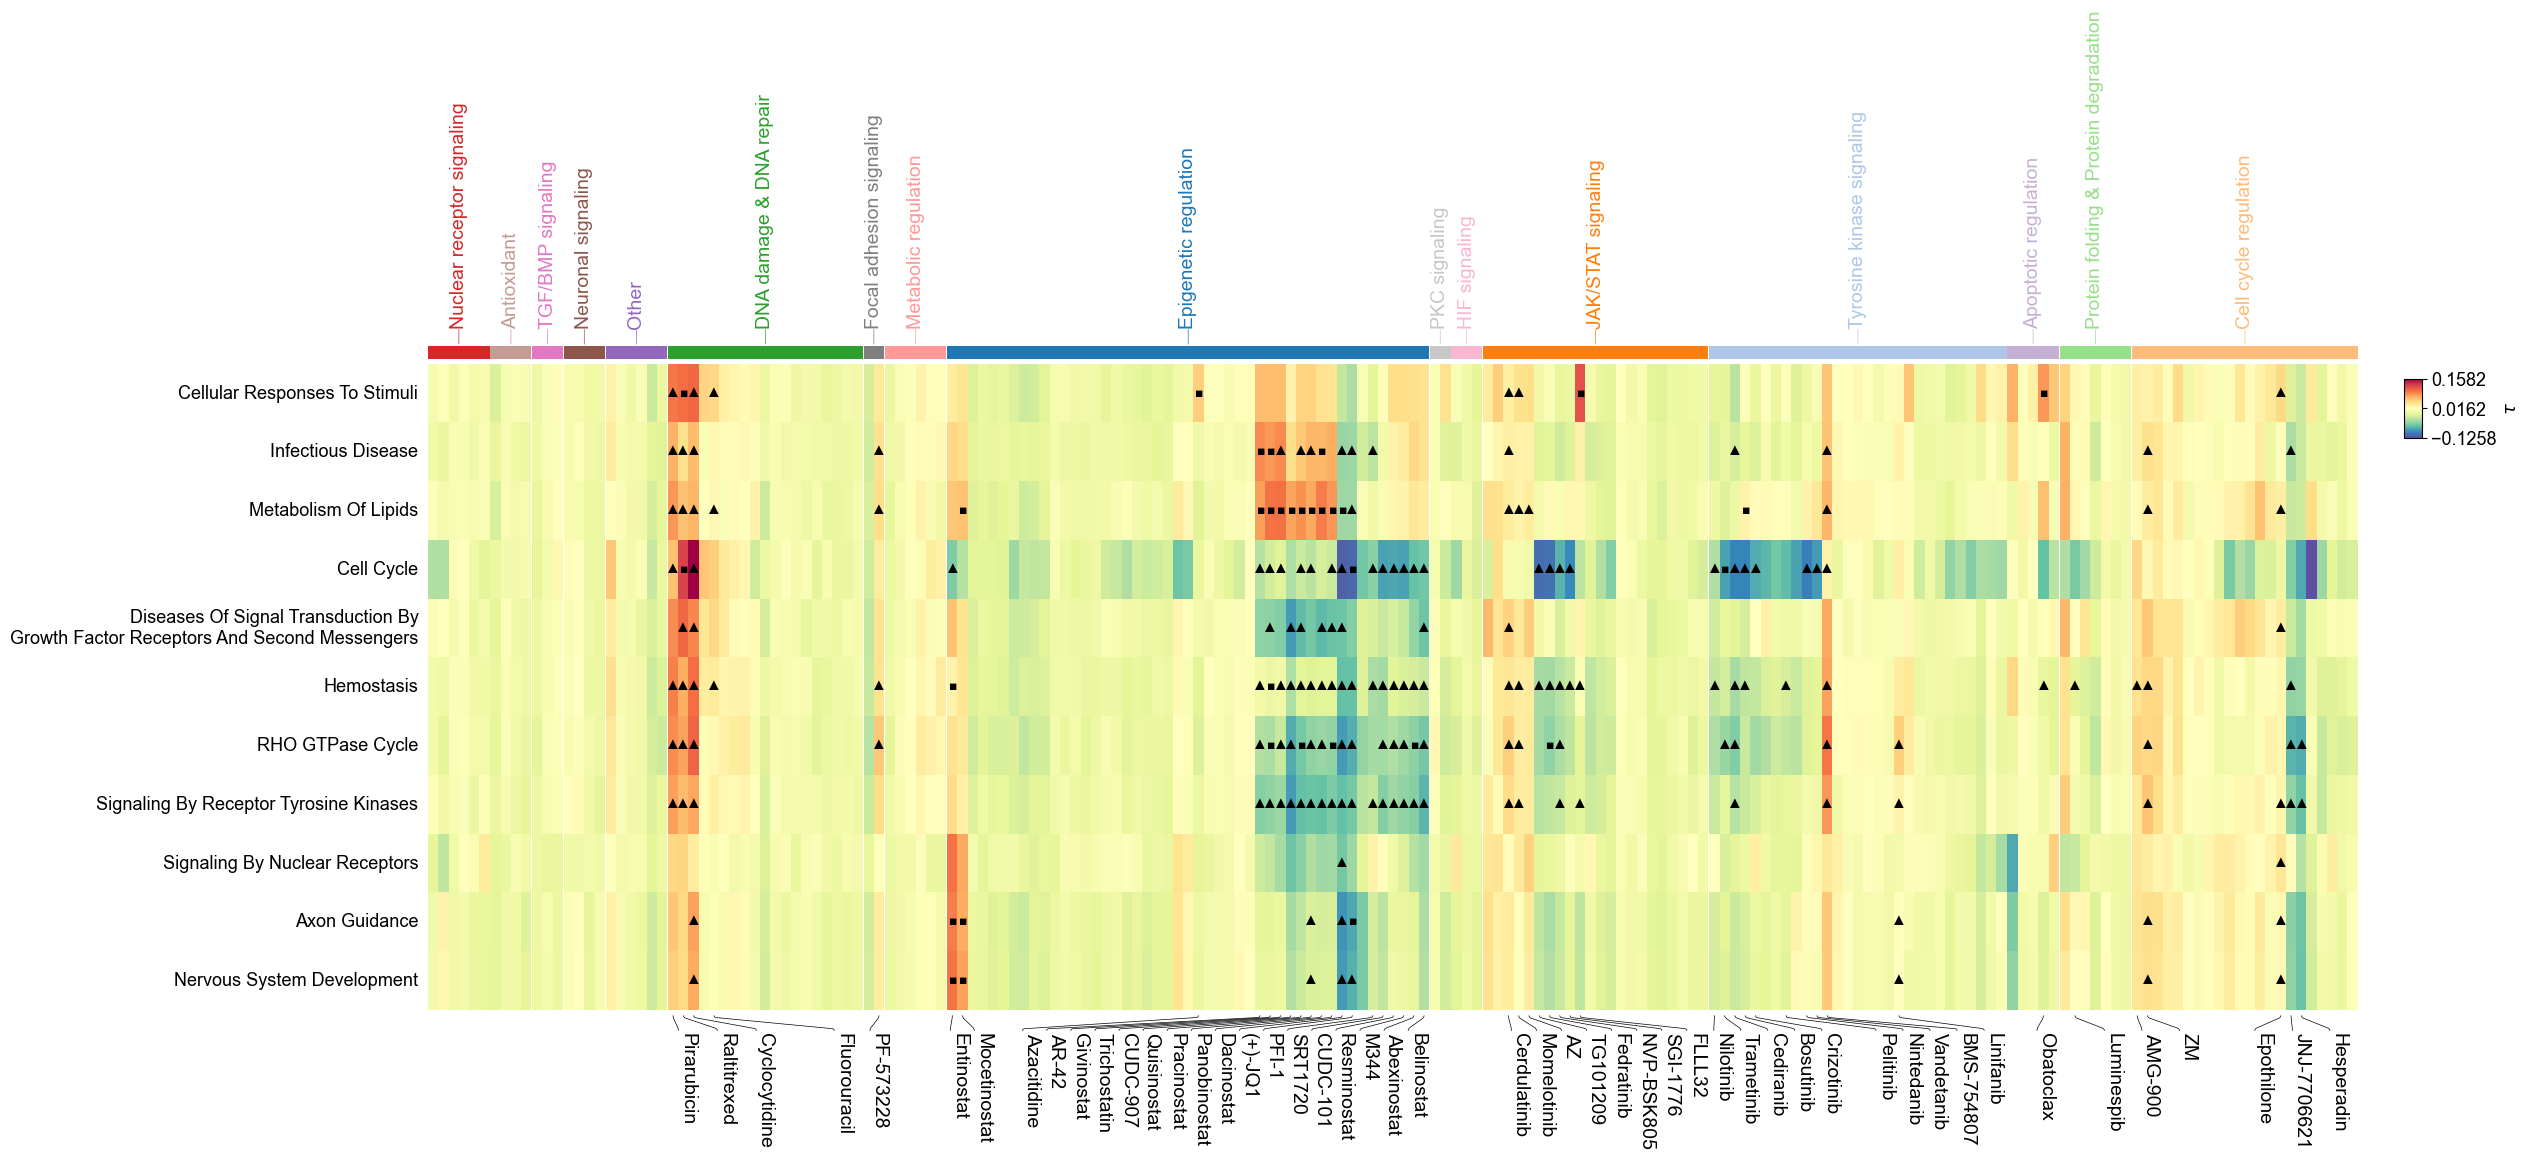

In [40]:
with plt.rc_context({'font.sans-serif': ['Arial']}):
    plt.figure(figsize=(25, 8))
    col_ha = HeatmapAnnotation(label=anno_label(row_df['level1'],merge=True,rotation=90,extend=True
                                                ,adjust_color=True,luminance=0.75,fontsize=14,
                                            relpos=(0.5,0)),
                               Group= anno_simple(row_df['level1'],legend=False,label=''),
                               axis=1)
    col_ha2 = HeatmapAnnotation(label = anno_label(row_df_annotated.product_name_short,merge=True,
                                                   extend=True,fontsize=14,
                                                   colors='black',
                                                  ), orientation = "down",
                                axis=1)
    cm = ClusterMapPlotter(data=tau_hat_df.T,  
                           top_annotation=col_ha,
                           bottom_annotation=col_ha2,
                           annot=annot.T,
                           fmt=None,
                           annot_kws={'color':'black','fontsize':10},
                           col_split=row_df.loc[:, ['level1']],
                           label=r'$\tau$',
                           row_dendrogram=False,
                           col_dendrogram=False,
                           show_rownames=True,
                           show_colnames=False,
                           row_names_side='left',
                           rasterized=True,
                           cmap=cmap,
                           legend_gap=5,
                           legend_hpad=10,
                           legend_vpad=5,
                           yticklabels_kws=dict(labelsize=13))
    cm.cbars[0].set_label(label=r'$\tau$',fontsize=13)
    cm.cbars[0].ax.tick_params(labelsize=13)
    plt.show()

Starting..
Calculating row orders..
Reordering rows..
Calculating col orders..
Reordering cols..
Plotting matrix..
Plotting HeatmapAnnotations
Plotting HeatmapAnnotations
Plotting legends..
Estimated legend width: 121.78027777777778 mm


/var/folders/19/48831_0d3pj_w2pnmx76ggyc0000gn/T/ipykernel_1493/3274191295.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


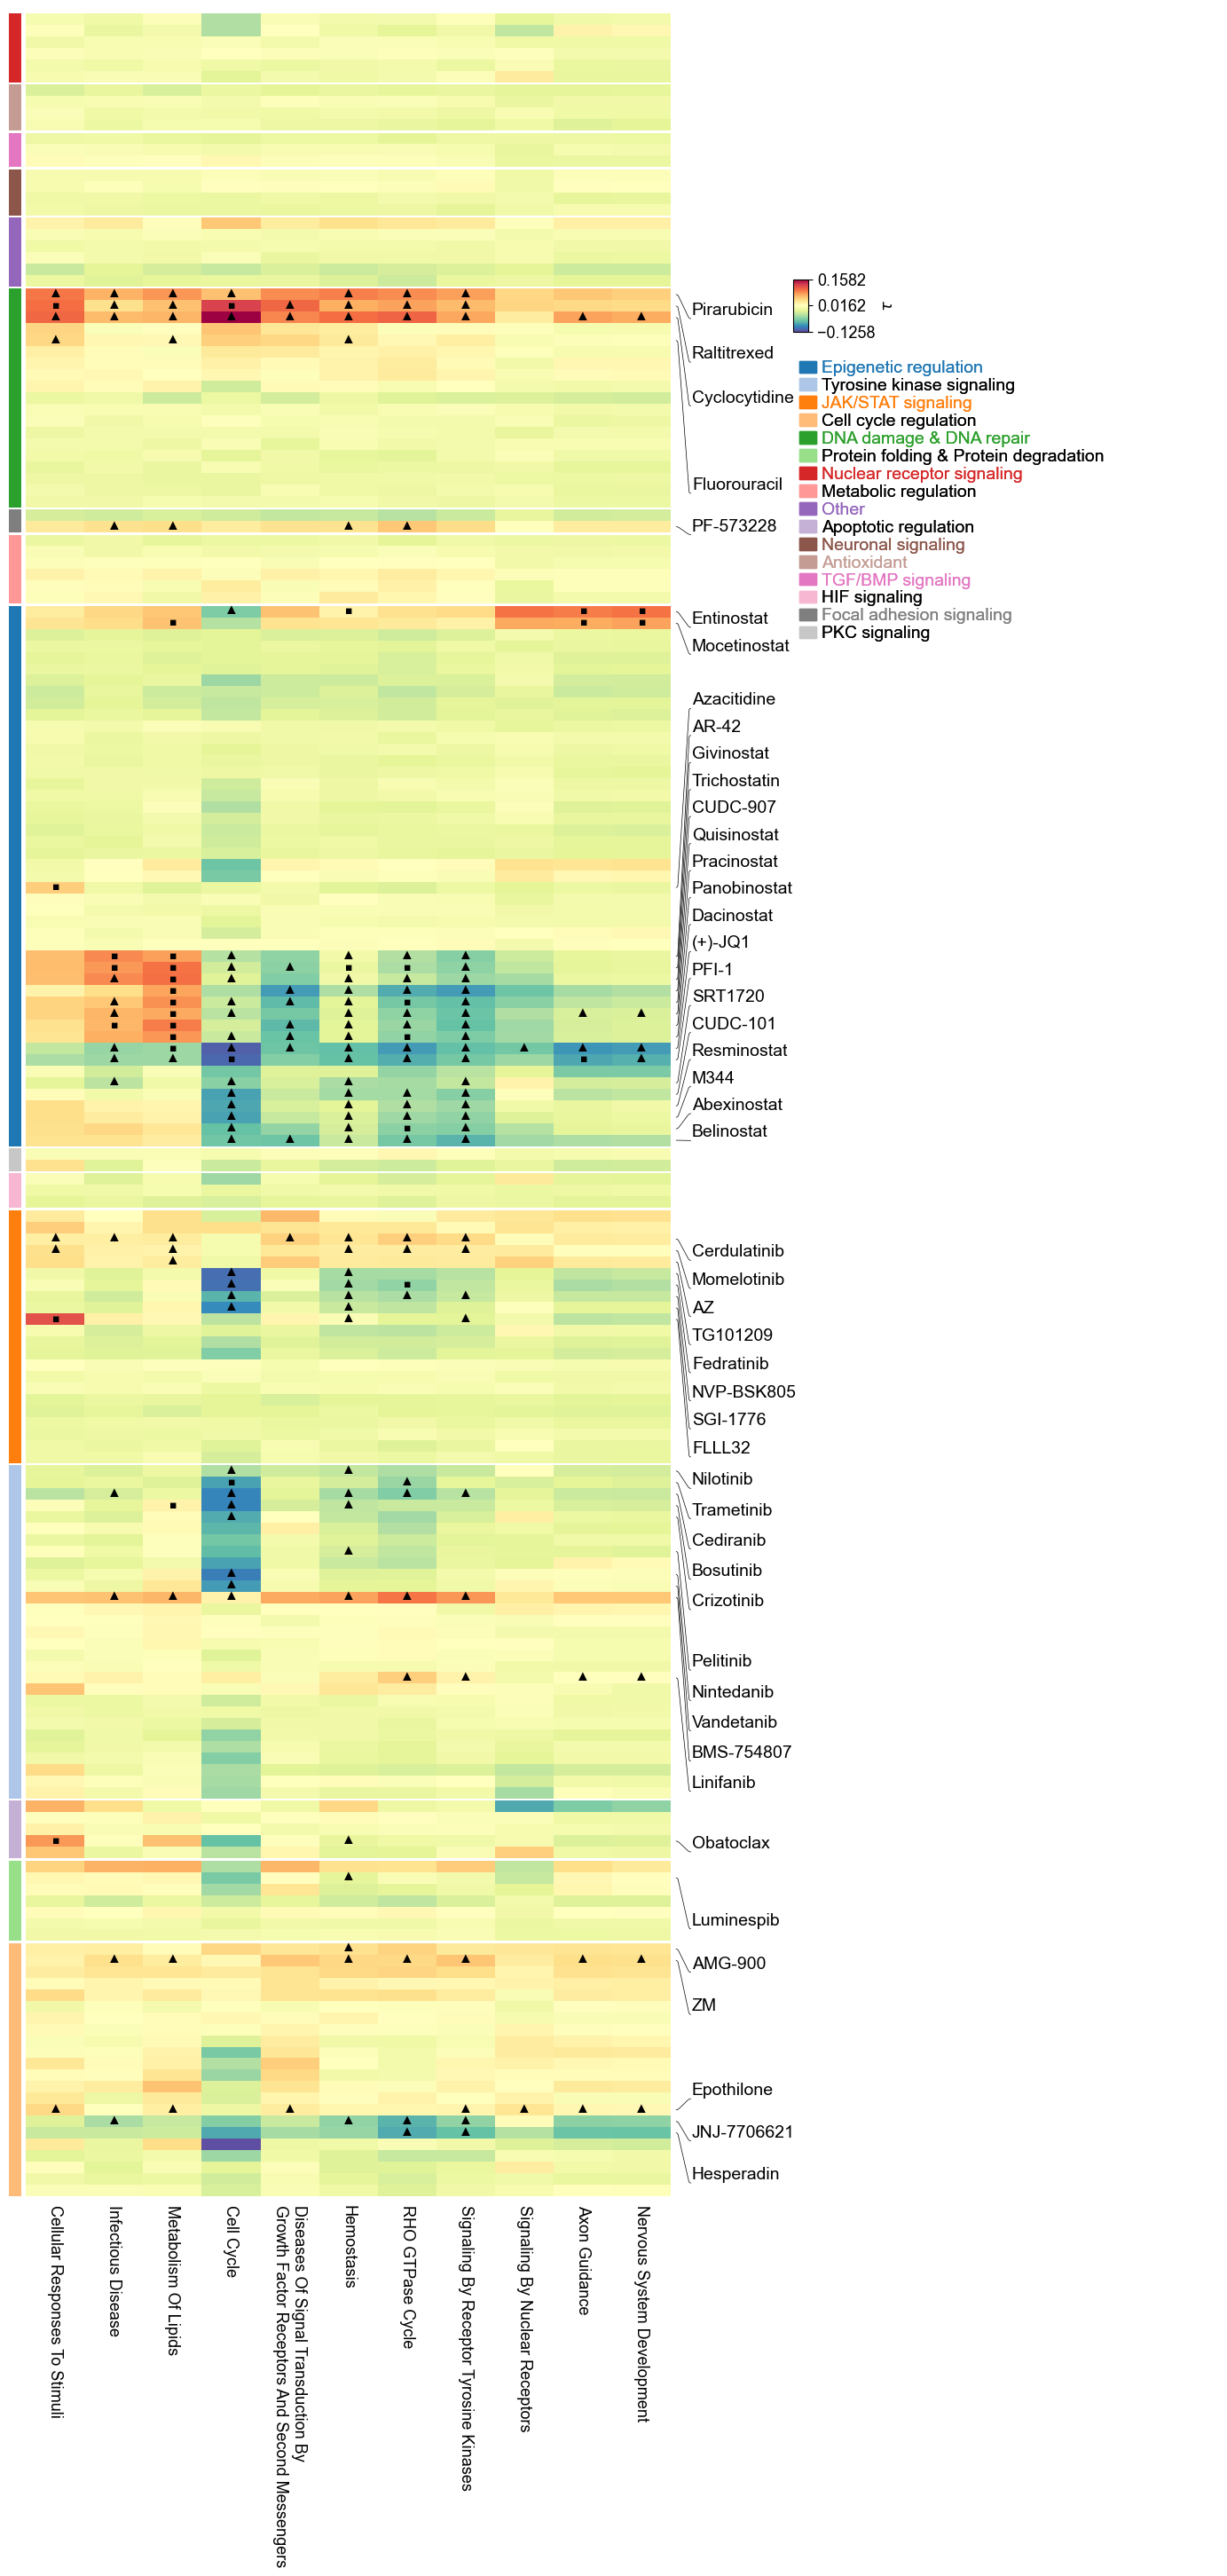

In [41]:
with plt.rc_context({'font.sans-serif': ['Arial']}):
    plt.figure(figsize=(8, 25))
    col_ha = HeatmapAnnotation(
                               Group= anno_simple(row_df['level1'],label='',
                                                  legend_kws={'frameon':False,'fontsize':14}),
                               axis=0)
    col_ha2 = HeatmapAnnotation(label = anno_label(row_df_annotated.product_name_short,merge=True,
                                                   extend=True,fontsize=14,
                                                   colors='black',
                                                  ), orientation = "right",
                                axis=0)
    cm = ClusterMapPlotter(data=tau_hat_df,  
                           left_annotation=col_ha,
                           right_annotation=col_ha2,
                           annot=annot,
                           fmt=None,
                           annot_kws={'color':'black','fontsize':10},
                           row_split=row_df.loc[:, ['level1']],
                           label=r'$\tau$',
                           row_dendrogram=False,
                           col_dendrogram=False,
                           show_rownames=False,
                           show_colnames=True,
                           rasterized=True,
                           cmap=cmap,
                           legend_gap=5,
                           legend_hpad=10,
                           legend_vpad=5,
                           xticklabels_kws=dict(labelsize=13))
    cm.cbars[0].set_label(label=r'$\tau$',fontsize=13)
    cm.cbars[0].ax.tick_params(labelsize=13)
    plt.tight_layout()
    #plt.savefig('all_figs/sciplexres/res_full.svg', format='svg',bbox_inches="tight")
    plt.show()

In [43]:
# selected drug
selected_drug = ['S1014', 'S1033', # Abl/Src
                 'S1529', 'S1454','S1048','S1181', # Aurora
                 'S7110', 'S1216', # Bromodomain
                 'S8567','S1168','S1122', 'S1090', 'S1030', 'S2759', 'S2627', 'S1085',
                 'S1045','S1422','S1396','S1053','S1095','S1703','S2693','S1194',
                 'S1515','S1129','S2170','S7792','S1096','S1484','S8502','S2012',
                 'S8481','S8323','S4125','S1541','S2244','S2779','S2804','S2818', # HDAC
                 'S7259', 'S2692', 'S2736', 'S2686','S2867','S2806', # JAK
                 'S1305', 'S1156', 'S1289', 'S1209', 'S1192', 'S3001', 'S1973', # Nucleotide analog
                 'S1010','S1017','S1361','S1056','S1178','S1032','S1319',
                 'S1363','S2718','S1264','S1046','S1143','S1068','S1577','S1028',# RTK
                 'S1003','S2158','S7634','S1012']

In [44]:
tau_hat_df_selected = tau_hat_df.loc[selected_drug]
annot_selected = annot.loc[selected_drug]
row_df_selected = row_df.loc[selected_drug]

Starting..
Calculating row orders..
Reordering rows..
Calculating col orders..
Reordering cols..
Plotting matrix..
Plotting HeatmapAnnotations
Plotting legends..
Estimated legend width: 63.53666666666667 mm


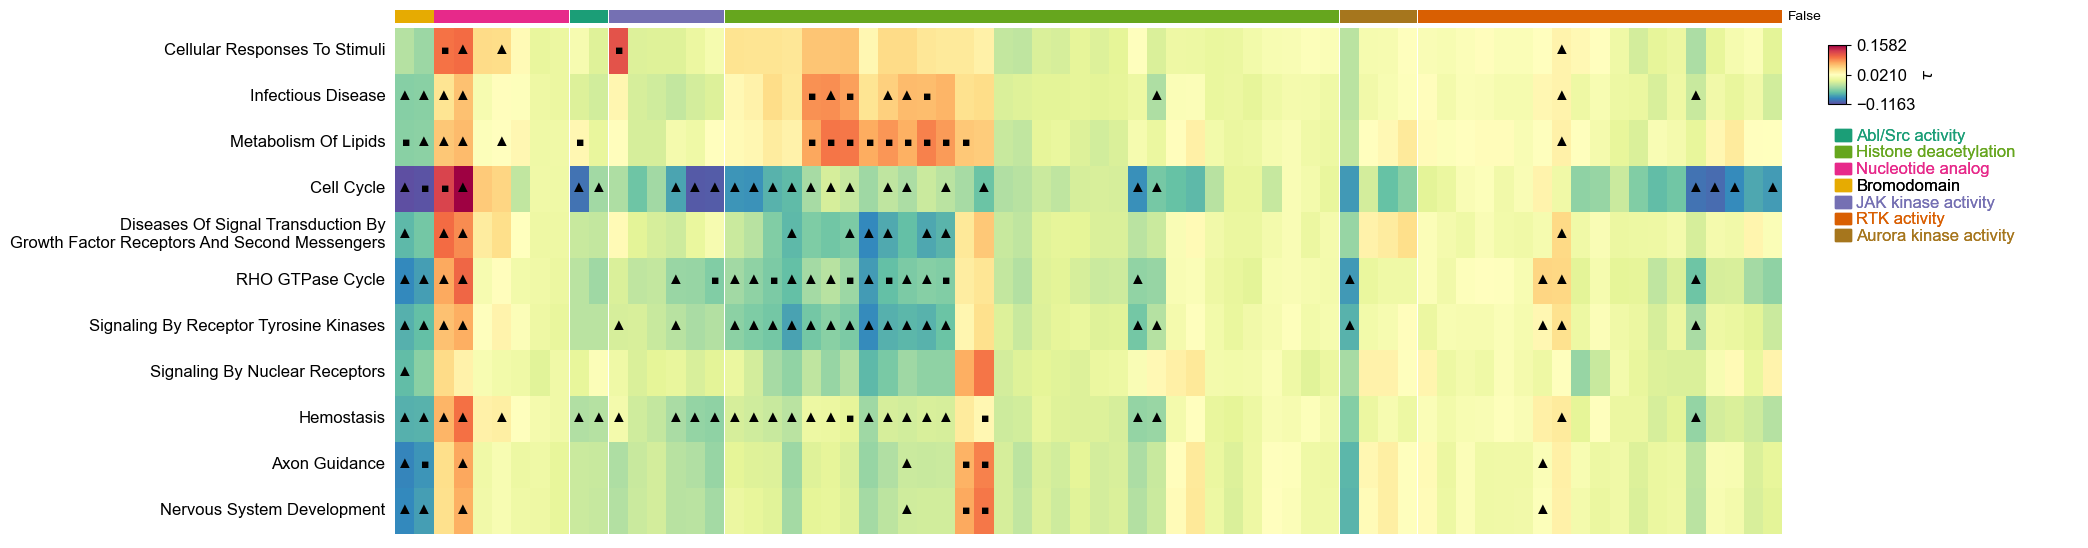

In [45]:
cmap_col=plt.cm.get_cmap('Dark2')
group_colors_dict={'Abl/Src activity':cmap_col(0),
                  'Histone deacetylation':cmap_col(4),
                  'Nucleotide analog':cmap_col(3),
                  'Bromodomain':cmap_col(5),
                  'JAK kinase activity':cmap_col(2),
                  'RTK activity':cmap_col(1),
                  'Aurora kinase activity':cmap_col(6)}
with plt.rc_context({'font.sans-serif': ['Arial']}):
    cmap = plt.cm.get_cmap('Spectral_r')
    plt.figure(figsize=(18, 6))
    col_ha = HeatmapAnnotation(Group= anno_simple(row_df_selected.level2, cmap = 'Dark2',label=False,
                                                  colors=group_colors_dict,
                                                  legend_kws={'frameon':False,'fontsize':12}),
                               axis=1)
    cm = ClusterMapPlotter(data=tau_hat_df_selected.T,  
                           top_annotation=col_ha,
                           annot=annot_selected.T,
                           fmt=None,
                           annot_kws={'color':'black','fontsize':10},
                           col_split=row_df_selected.loc[:, ['level2']],
                           label=r'$\tau$',
                           row_dendrogram=False,
                           col_dendrogram=False,
                           show_rownames=True,
                           show_colnames=False,
                           row_names_side='left',
                           rasterized=True,
                           cmap=cmap,
                           legend_gap=5,
                           legend_hpad=10,
                           legend_vpad=5,
                           yticklabels_kws=dict(labelsize=12))
    cm.cbars[0].set_label(label=r'$\tau$',fontsize=12)
    cm.cbars[0].ax.tick_params(labelsize=12)
    #plt.tight_layout()
    #plt.savefig('all_figs/sciplexres/res.svg', format='svg')
    plt.show()

In [46]:
row_order = ['Cellular Responses To Stimuli',
  'Infectious Disease',
  'Metabolism Of Lipids',
  'Diseases Of Signal Transduction By\nGrowth Factor Receptors And Second Messengers',
  'RHO GTPase Cycle',
  'Signaling By Receptor Tyrosine Kinases',
  'Signaling By Nuclear Receptors',
  'Hemostasis',
  'Axon Guidance',
  'Nervous System Development',
            'Cell Cycle']
tau_hat_df_selected = tau_hat_df_selected[row_order]
annot_selected = annot_selected[row_order]
drug_class_full=cm.col_order
drug_list=[]
drug_class_list=[]
for i in range(len(drug_class_full)):
    for drug in drug_class_full[i]:
        drug_list.append(drug)
        drug_class_list.append(i)
drug_class_dict=dict(zip(drug_list,drug_class_list))
change_dict={3:2,6:1,5:6,4:4,1:3,0:5,2:0}
for key in drug_class_dict.keys():
    drug_class_dict[key] = change_dict[drug_class_dict[key]]

In [47]:
annotated_drug = ['S1014', 'S1033', # Abl/Src
                  'S7110', 'S1216', # Bromodomain
                  'S1053','S1122','S1045','S1095','S1515','S2170','S2244','S2693','S2779',# HDAC
                  'S7259','S2686','S2736','S2692', # JAK
                  'S1192', 'S1973', # Nucle
                  'S1010','S1017','S1046','S1068'# RTK
                 ]
row_df_annotated = row_df_selected.copy()
row_df_annotated.loc[
    ~row_df_annotated.index.isin(annotated_drug),
    'product_name_short'
] = None
cmap_col=plt.cm.get_cmap('Dark2')
colors_dict={}
for g in annotated_drug:
    product_name = row_df_annotated.loc[g].product_name_short
    colors_dict[product_name]=cmap_col(drug_class_dict[g])

Starting..
Calculating row orders..
Reordering rows..
Calculating col orders..
Reordering cols..
Plotting matrix..
Plotting HeatmapAnnotations
Plotting HeatmapAnnotations
Plotting legends..
Estimated legend width: 73.62611111111111 mm


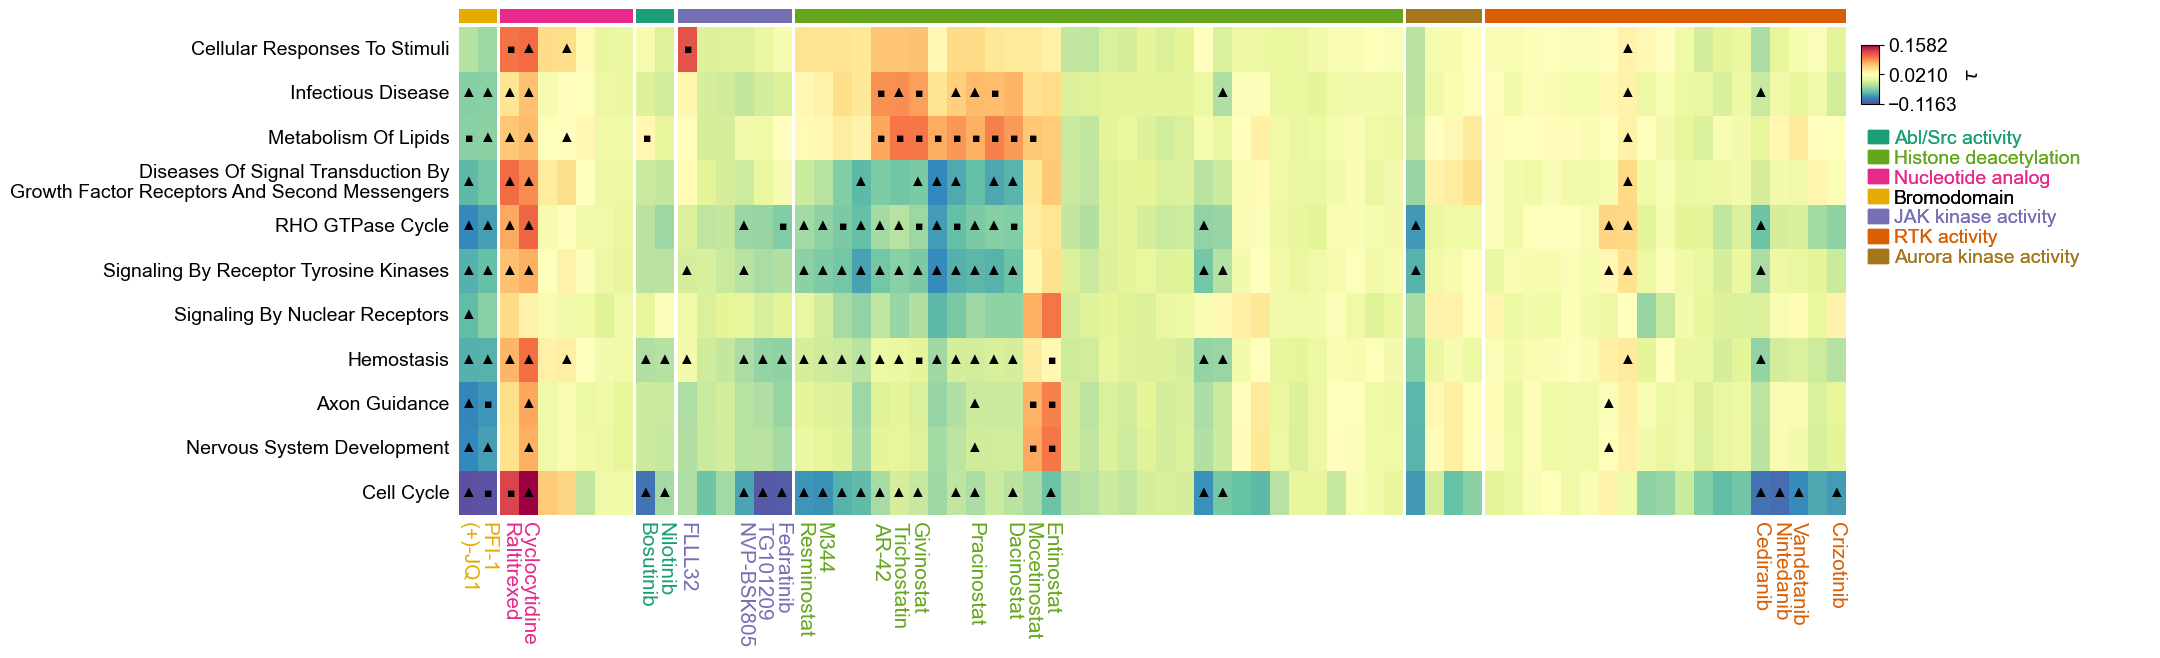

In [50]:
with plt.rc_context({'font.sans-serif': ['Arial']}):
    cmap = plt.cm.get_cmap('Spectral_r')
    plt.figure(figsize=(18, 6))
    col_ha2 = HeatmapAnnotation(label = anno_label(row_df_annotated.product_name_short,merge=True,
                                                   extend=False,
                                                   rotation=270,
                                                   fontsize=15,
                                                   colors=colors_dict,
                                                   arrowprops = dict(visible=False)
                                                  ),
                                axis=1)
    col_ha = HeatmapAnnotation(Group= anno_simple(row_df_selected.level2, cmap = 'Dark2',label='',
                                                  colors=group_colors_dict,
                                                  legend_kws={'frameon':False,'fontsize':14}),
                               axis=1)
    cm = ClusterMapPlotter(data=tau_hat_df_selected.T,
                           bottom_annotation=col_ha2,
                           top_annotation=col_ha,
                           annot=annot_selected.T,
                           fmt=None,
                           annot_kws={'color':'black','fontsize':10},
                           col_split=row_df_selected.loc[:, ['level2']],
                           label=r'$\tau$',
                           row_cluster=False,
                           row_dendrogram=False,
                           col_dendrogram=False,
                           show_rownames=True,
                           show_colnames=False,
                           row_names_side='left',
                           rasterized=True,
                           cmap=cmap,
                           col_split_gap=0.8,
                           legend_gap=5,
                           legend_hpad=2,
                           legend_vpad=5,
                           yticklabels_kws=dict(labelsize=14))
    cm.cbars[0].set_label(label=r'$\tau$',fontsize=14)
    cm.cbars[0].ax.tick_params(labelsize=14)
    #plt.tight_layout()
    #plt.savefig('all_figs/sciplexres/res.svg', format='svg',bbox_inches="tight")
    plt.show()

# Abl/Src, RTK, JAK

In [51]:
# Abl/Src
cell_lines = ['K562','A549','MCF7']
drawing_data = {}
drug_list = ['S1033', 'S1014']
path = 'AblSrc'
Y_path = 'cellcycle'
for drug in drug_list:
    product_name = drug_name_dict[drug]
    product_name = product_name.split(' ')[0]
    drawing_data[product_name]={}
    final_res_df = pd.read_csv('sciplex3_res/path_res/{}_{}_{}_test2.csv'.format(path,Y_path,drug),index_col=0)
    expr_list = []
    for cellline in cell_lines:
        expr_list.append(final_res_df[final_res_df.group==cellline]['tau_hat'].values[0])
    drawing_data[product_name]['expr'] = expr_list

    AUC_df = pd.read_csv('sciplex3_res/path_res/{}_AUC.csv'.format(path),index_col=0)
    AUC_list = []
    for cellline in cell_lines:
        AUC_list.append(AUC_df.loc[cellline][product_name])
    drawing_data[product_name]['AUC'] = AUC_list

    IC50_df = pd.read_csv('sciplex3_res/path_res/{}_IC50.csv'.format(path),index_col=0)
    IC50_list = []
    for cellline in ['K562','A549','MCF7']:
        IC50_list.append(np.log10(IC50_df.loc[cellline][product_name]))
    drawing_data[product_name]['logIC50'] = IC50_list

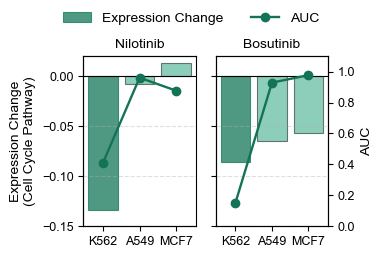

In [54]:
with plt.rc_context({'figure.figsize': (4, 2.6),'font.sans-serif':['Arial']}):
    cmap_col=plt.cm.get_cmap('Dark2')
    fig, axes = plt.subplots(
        1, 2,
        sharey=True,
        constrained_layout=True
    )
    base_color = np.array(cmap_col(0)[:3])   
    darker_color = tuple(base_color * 0.73)  
    darker_color2 = tuple(base_color * 0.75) 
    bar_color = base_color #"#8FB6D8"     # gene expression
    line_color = darker_color #"#1F4E99"    # AUC
    ax2_last = None
    for i, (ax, (drug, values)) in enumerate(zip(axes, drawing_data.items())):
        x = np.arange(len(cell_lines))
        # ---- bar: gene expression change ----
        bars = ax.bar(
            x,
            values["expr"],
            color=bar_color,
            edgecolor="black",
            linewidth=0.8,
            label="Expression Change"
        )
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(cell_lines,fontsize=9)
        ax.tick_params(axis='y', labelsize=9)
        ax.set_title(drug, fontsize=10)
        ax.set_ylim(-0.15, 0.02)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        # ---- line：logIC50 ----
        ax2 = ax.twinx()
        ax2.plot(
            x,
            values["AUC"],
            color=line_color,
            marker="o",
            linewidth=1.7,
            label="AUC"
        )
        ax2.tick_params(axis='y', labelsize=9)
        ax2.set_ylim(0, 1.1)
        if i != len(axes) - 1:
            ax2.set_yticks([])
            ax2.spines["right"].set_visible(False)
        else:
            ax2_last = ax2

        for bar in bars:
            bar.set_alpha(0.5)
            highlight_idx = 0  # K562
            bars[highlight_idx].set_alpha(0.75)
            bars[highlight_idx].set_color(darker_color2)
    axes[0].set_ylabel(
        "Expression Change\n(Cell Cycle Pathway)",
        fontsize=10
    )
    ax2_last.set_ylabel("AUC", fontsize=10)
    handles_left, labels_left = axes[-1].get_legend_handles_labels()
    handles_right, labels_right = ax2_last.get_legend_handles_labels()
    handles = handles_left + handles_right
    labels = labels_left + labels_right
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2,
        fontsize=10,
        frameon=False
    )
    plt.tight_layout(rect=[0, 0, 1, 0.92])  
    #plt.savefig('all_figs/sciplexres/AblSrc_cellcycle.svg', format='svg',bbox_inches="tight")
    plt.show()

In [56]:
# RTK
cell_lines = ['K562','A549','MCF7']
drawing_data = {}
drug_list = ['S1010', 'S1046', 'S1068','S1017']
path = 'RTK'
Y_path = 'cellcycle'
for drug in drug_list:
    product_name = drug_name_dict[drug]
    product_name = product_name.split(' ')[0]
    drawing_data[product_name]={}

    final_res_df = pd.read_csv('sciplex3_res/path_res/{}_{}_{}_test2.csv'.format(path,Y_path,drug),index_col=0)
    expr_list = []
    for cellline in cell_lines:
        expr_list.append(final_res_df[final_res_df.group==cellline]['tau_hat'].values[0])
    drawing_data[product_name]['expr'] = expr_list
    AUC_df = pd.read_csv('sciplex3_res/path_res/{}_AUC.csv'.format(path),index_col=0)
    AUC_list = []
    for cellline in cell_lines:
        AUC_list.append(AUC_df.loc[cellline][product_name])
    drawing_data[product_name]['AUC'] = AUC_list
    IC50_df = pd.read_csv('sciplex3_res/path_res/{}_IC50.csv'.format(path),index_col=0)
    IC50_list = []
    for cellline in ['K562','A549','MCF7']:
        IC50_list.append(np.log10(IC50_df.loc[cellline][product_name]))
    drawing_data[product_name]['logIC50'] = IC50_list

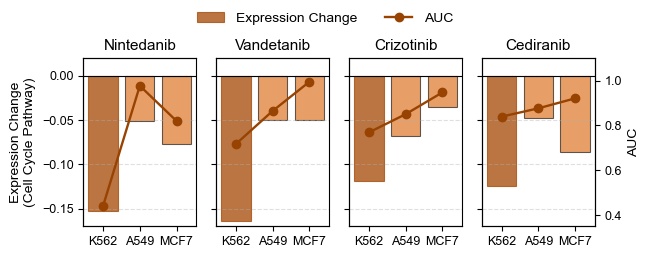

In [57]:
with plt.rc_context({'figure.figsize': (5/3*4, 2.6),'font.sans-serif':['Arial']}):
    fig, axes = plt.subplots(
        1, 4,
        sharey=True,
        constrained_layout=True
    )
    base_color = np.array(cmap_col(1)[:3])   
    darker_color = tuple(base_color * 0.7)  
    darker_color2 = tuple(base_color * 0.75) 
    bar_color = base_color#"#8FB6D8"     # gene expression
    line_color = darker_color #"#1F4E99"    # AUC
    ax2_last = None
    for i, (ax, (drug, values)) in enumerate(zip(axes, drawing_data.items())):
        x = np.arange(len(cell_lines))
        # ---- bar: gene expression change ----
        bars = ax.bar(
            x,
            values["expr"],
            color=bar_color,
            edgecolor="black",
            linewidth=0.8,
            label="Expression Change"
        )
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(cell_lines,fontsize=9)
        ax.tick_params(axis='y', labelsize=9)
        ax.set_title(drug, fontsize=11)
        ax.set_ylim(-0.17, 0.02)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        # ---- line：logIC50 ----
        ax2 = ax.twinx()
        ax2.plot(
            x,
            values["AUC"],
            color=line_color,
            marker="o",
            linewidth=1.7,
            label="AUC"
        )
        ax2.set_ylim(0.35, 1.1)
        ax2.tick_params(axis='y', labelsize=9)
        if i != len(axes) - 1:
            ax2.set_yticks([])
            ax2.spines["right"].set_visible(False)
        else:
            ax2_last = ax2

        for bar in bars:
            bar.set_alpha(0.6)
            highlight_idx = 0  # K562
            bars[highlight_idx].set_alpha(0.75)
            bars[highlight_idx].set_color(darker_color2)
    axes[0].set_ylabel(
        "Expression Change\n(Cell Cycle Pathway)",
        fontsize=10
    )
    ax2_last.set_ylabel("AUC", fontsize=10)
    handles_left, labels_left = axes[-1].get_legend_handles_labels()
    handles_right, labels_right = ax2_last.get_legend_handles_labels()
    handles = handles_left + handles_right
    labels = labels_left + labels_right
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2,
        fontsize=10,
        frameon=False
    )
    plt.tight_layout(rect=[0, 0, 1, 0.92])  
    #plt.savefig('all_figs/sciplexres/RTK_cellcycle.svg', format='svg',bbox_inches="tight")
    plt.show()

In [58]:
# JAK
cell_lines = ['K562','A549','MCF7']
drawing_data = {}
drug_list = ['S2736', 'S2686']
path = 'JAK'
Y_path = 'cellcycle'
for drug in drug_list:
    product_name = drug_name_dict[drug]
    product_name = product_name.split(' ')[0]
    drawing_data[product_name]={}
    final_res_df = pd.read_csv('sciplex3_res/path_res/{}_{}_{}_test2.csv'.format(path,Y_path,drug),index_col=0)
    expr_list = []
    for cellline in cell_lines:
        expr_list.append(final_res_df[final_res_df.group==cellline]['tau_hat'].values[0])
    drawing_data[product_name]['expr'] = expr_list
    AUC_df = pd.read_csv('sciplex3_res/path_res/{}_AUC.csv'.format(path),index_col=0)
    AUC_list = []
    for cellline in cell_lines:
        AUC_list.append(AUC_df.loc[cellline][product_name])
    drawing_data[product_name]['AUC'] = AUC_list
    IC50_df = pd.read_csv('sciplex3_res/path_res/{}_IC50.csv'.format(path),index_col=0)
    IC50_list = []
    for cellline in ['K562','A549','MCF7']:
        IC50_list.append(np.log10(IC50_df.loc[cellline][product_name]))
    drawing_data[product_name]['logIC50'] = IC50_list

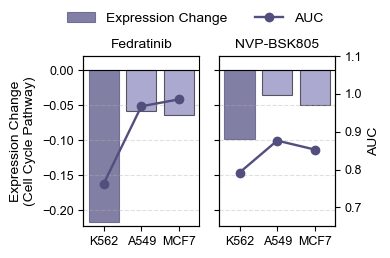

In [59]:
with plt.rc_context({'figure.figsize': (4, 2.6),'font.sans-serif':['Arial']}):
    fig, axes = plt.subplots(
        1, 2,
        #figsize=(4, 2.6),
        sharey=True,
        constrained_layout=True
    )
    base_color = np.array(cmap_col(2)[:3])   
    darker_color = tuple(base_color * 0.7)  
    darker_color2 = tuple(base_color * 0.75) 
    bar_color = base_color#"#8FB6D8"     # gene expression
    line_color = darker_color #"#1F4E99"    # AUC
    ax2_last = None
    for i, (ax, (drug, values)) in enumerate(zip(axes, drawing_data.items())):
        x = np.arange(len(cell_lines))
        # ---- bar: gene expression change ----
        bars = ax.bar(
            x,
            values["expr"],
            color=bar_color,
            edgecolor="black",
            linewidth=0.8,
            label="Expression Change"
        )
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(cell_lines,fontsize=9)
        ax.tick_params(axis='y', labelsize=9)
        ax.set_title(drug, fontsize=10)
        ax.set_ylim(-0.223, 0.02)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        # ---- line: logIC50 ----
        ax2 = ax.twinx()
        ax2.plot(
            x,
            values["AUC"],
            color=line_color,
            marker="o",
            linewidth=1.7,
            label="AUC"
        )
        ax2.set_ylim(0.65, 1.1)
        ax2.tick_params(axis='y', labelsize=9)
        if i != len(axes) - 1:
            ax2.set_yticks([])
            ax2.spines["right"].set_visible(False)
        else:
            ax2_last = ax2

        for bar in bars:
            bar.set_alpha(0.6)
            highlight_idx = 0  # K562
            bars[highlight_idx].set_alpha(0.75)
            bars[highlight_idx].set_color(darker_color2)
    axes[0].set_ylabel(
        "Expression Change\n(Cell Cycle Pathway)",
        fontsize=10
    )
    ax2_last.set_ylabel("AUC", fontsize=10)
    handles_left, labels_left = axes[-1].get_legend_handles_labels()
    handles_right, labels_right = ax2_last.get_legend_handles_labels()
    handles = handles_left + handles_right
    labels = labels_left + labels_right
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2,
        fontsize=10,
        frameon=False
    )
    plt.tight_layout(rect=[0, 0, 1, 0.92])  
    #plt.savefig('all_figs/sciplexres/JAK_cellcycle.svg', format='svg',bbox_inches="tight")
    plt.show()

# FLLL32

In [65]:
adata_S7259=sc.read_h5ad('sciplex3_res/path_res/S7259_Stimuli_adata.h5ad')

In [71]:
path = 'JAK'
drug = 'S7259' 
product_name = drug_name_dict[drug].split(' ')[0]
Y_path = 'Stimuli'
final_res_df = pd.read_csv('sciplex3_res/path_res/{}_{}_{}_test2.csv'.format(path,Y_path,drug),index_col=0)
err_list=[]
for i in range(len(final_res_df)):
    err_list.append(stats.norm.interval(1-0.05, loc=0, scale=final_res_df.iloc[i,:]['tau_sd'])[1])
final_res_df['95_err']=err_list
final_res_df.sort_values('tau_hat', inplace=True,ascending=True)
tau_hat_all = tau_hat_df.loc[drug]['Cellular Responses To Stimuli']
tau_sd_all = tau_sd_df.loc[drug]['Cellular Responses To Stimuli']
pval1 = pval1_df.loc[drug]['Cellular Responses To Stimuli']

In [68]:
final_res_df # test2 results

,group,p_val,tau_hat,tau_sd,tau_star,sks_obs,95_err
2,A549,0.494,0.065262,0.010780,0.070863,0.064007,0.021129
1,K562,0.172,0.069200,0.021351,0.058107,0.124491,0.041847
0,MCF7,0.026,0.177545,0.009104,0.160202,0.167962,0.017844


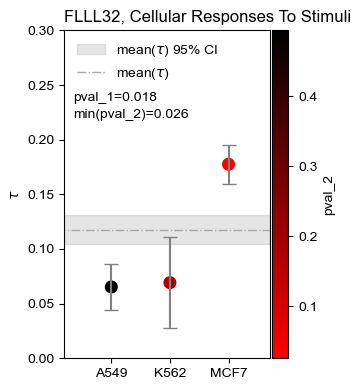

In [74]:
with plt.rc_context({'figure.figsize': (3.5, 4),'font.sans-serif':['Arial']}):
    rbcmap = mplc.LinearSegmentedColormap.from_list("", ["red","black"])
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ax.errorbar(final_res_df['group'], final_res_df['tau_hat'], yerr = final_res_df['95_err'], ls = "None", capsize=5,color = "grey")
    im=ax.scatter(final_res_df['group'], final_res_df['tau_hat'],  marker = "o", c = final_res_df['p_val'],s=70,cmap=rbcmap)
    ax.set_ylabel(r'$\tau$')
    cbar=plt.colorbar(im,ax=ax,pad=0.01)
    cbar.set_label('pval_2', rotation=90)
    plt.xlim([-0.8,2.7])
    plt.ylim([0,0.3])

    all_CI_min,all_CI_max=stats.norm.interval(1-0.05, loc=tau_hat_all, scale=tau_sd_all)
    ax.fill_between([-1.6,2.7],all_CI_min,all_CI_max,alpha=0.2, color='grey', label = r'mean($\tau$) 95% CI')
    ax.hlines(y=tau_hat_all, xmin=-1.7, xmax=2.7, linewidth=1, color='darkgrey',linestyle='-.',label=r'mean($\tau$)')
    plt.legend(frameon=False,loc='upper left')
    
    ax.text(-0.65,0.235,'pval_1={}'.format(round(pval1,3)))
    ax.text(-0.65,0.22,'min(pval_2)={}'.format(round(final_res_df.p_val.min(),3)))
    plt.title('{}, Cellular Responses To Stimuli'.format(product_name),loc='left')
    plt.tight_layout()
    #plt.savefig('all_figs/sciplexres/JAK_FLLL32_Stimuli.svg', format='svg',bbox_inches="tight")
    plt.show()

In [62]:
UMAP_drawing_df = pd.DataFrame(adata_S7259.obsm['X_umap'],columns=['UMAP1','UMAP2'])
UMAP_drawing_df['condition'] = adata_S7259.obs.product_name.values
UMAP_drawing_df['Y'] = adata_S7259.obs.Y.values

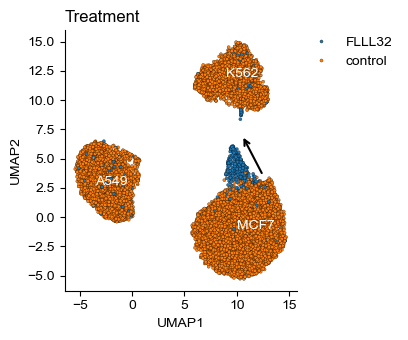

In [63]:
with plt.rc_context({'figure.figsize': (4.2, 3.5),'font.sans-serif':['Arial']}): 
    markers_dict = {'FLLL32': '^', 'control':'o'}
    ax = sns.scatterplot(
        data=UMAP_drawing_df,
        x="UMAP1",
        y="UMAP2",
        hue="condition",
        edgecolor='black',
        s=5)
    leg = ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
    leg.get_frame().set_linewidth(0)   
    leg.set_title("") 
    plt.text(10,-1,'MCF7',fontsize=10,color='white')
    plt.text(-3.5,2.7,'A549',fontsize=10, color='white')
    plt.text(9,12,'K562',fontsize=10, color = 'white')
    plt.annotate(
    '', xy=(10.5, 7), xytext=(12.5, 3.55),
    arrowprops=dict(arrowstyle='->', linewidth=1.5))
    plt.title(
    'Treatment',
    loc='left')
    sns.despine()
    plt.tight_layout()
    #plt.savefig('all_figs/sciplexres/FLLL32_UMAP1.png',bbox_inches="tight")
    plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


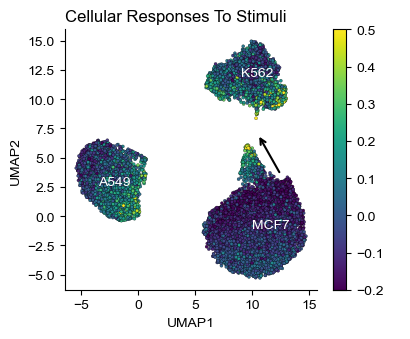

In [64]:
with plt.rc_context({'figure.figsize': (4.2, 3.5),'font.sans-serif':['Arial']}): 
    markers_dict = {'FLLL32': '^', 'control':'o'}
    ax = sns.scatterplot(
        data=UMAP_drawing_df,
        x="UMAP1",
        y="UMAP2",
        hue="Y",
        palette='viridis',
        hue_norm=(-0.2, 0.5),
        edgecolor='black',
        s=5,
        legend=False)
    norm = mpl.colors.Normalize(vmin=-0.2, vmax=0.5)
    sm = mpl.cm.ScalarMappable(cmap='viridis', norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax)
    cbar.set_label(" ")
    leg = ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
    leg.get_frame().set_linewidth(0)   
    leg.set_title("") 
    plt.text(10,-1,'MCF7',fontsize=10,color='white')
    plt.text(-3.5,2.7,'A549',fontsize=10, color='white')
    plt.text(9,12,'K562',fontsize=10, color = 'white')
    plt.annotate(
    '', xy=(10.5, 7), xytext=(12.5, 3.55),
    arrowprops=dict(arrowstyle='->', linewidth=1.5))
    plt.title(
    'Cellular Responses To Stimuli',
    loc='left')
    sns.despine()
    plt.tight_layout()
    #plt.savefig('all_figs/sciplexres/FLLL32_UMAP2.png', bbox_inches="tight")
    plt.show()